# 3. Models from class: Random Forest and MLP

Both are evaluated with **5-fold cross-validation grouped by patient**: every patient is scored by a
model that never saw any of their encounters. Decision thresholds are also tuned on the other folds.
The first run trains the models (several minutes); later runs read cached scores.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False})

In [2]:
from workflow_ml.config import LABELS
from workflow_ml.features import load_table
from workflow_ml.split import patient_folds
from workflow_ml.train import BASE_MODELS, cached_scores, out_of_fold_decisions
from workflow_ml.evaluate import score_table

table = load_table()
folds = patient_folds(table)
y_true = table[list(LABELS)].to_numpy()


def evaluate(name, make_model=None):
    """Out-of-fold scores and metrics for one model (cached after the first run)."""
    scores = cached_scores(name, make_model or BASE_MODELS[name], table, folds)
    decisions = out_of_fold_decisions(scores, y_true, folds)
    return scores, score_table(y_true, scores, decisions).assign(model=name)

## Random Forest — bagging of decision trees

In [3]:
forest_scores, forest_metrics = evaluate("random_forest")
print("mean F1:", forest_metrics["f1"].mean().round(3))
forest_metrics[["label", "precision", "recall", "f1", "pr_auc", "roc_auc"]].round(3)

mean F1: 0.745


,label,precision,recall,f1,pr_auc,roc_auc
0,medical_exam,0.591,0.790,0.676,0.649,0.913
1,lab_test,0.796,0.842,0.818,0.889,0.968
2,imaging,0.641,0.676,0.658,0.675,0.923
3,instrument_test,0.862,0.798,0.829,0.785,0.962


## Multi-layer perceptron — backpropagation
Inputs are log-scaled and standardised; categories are one-hot encoded (`workflow_ml/preprocess.py`).

In [4]:
mlp_scores, mlp_metrics = evaluate("mlp")
print("mean F1:", mlp_metrics["f1"].mean().round(3))
mlp_metrics[["label", "precision", "recall", "f1", "pr_auc", "roc_auc"]].round(3)

mean F1: 0.606


,label,precision,recall,f1,pr_auc,roc_auc
0,medical_exam,0.483,0.677,0.564,0.548,0.854
1,lab_test,0.712,0.757,0.734,0.789,0.931
2,imaging,0.679,0.668,0.673,0.671,0.897
3,instrument_test,0.497,0.415,0.452,0.596,0.927


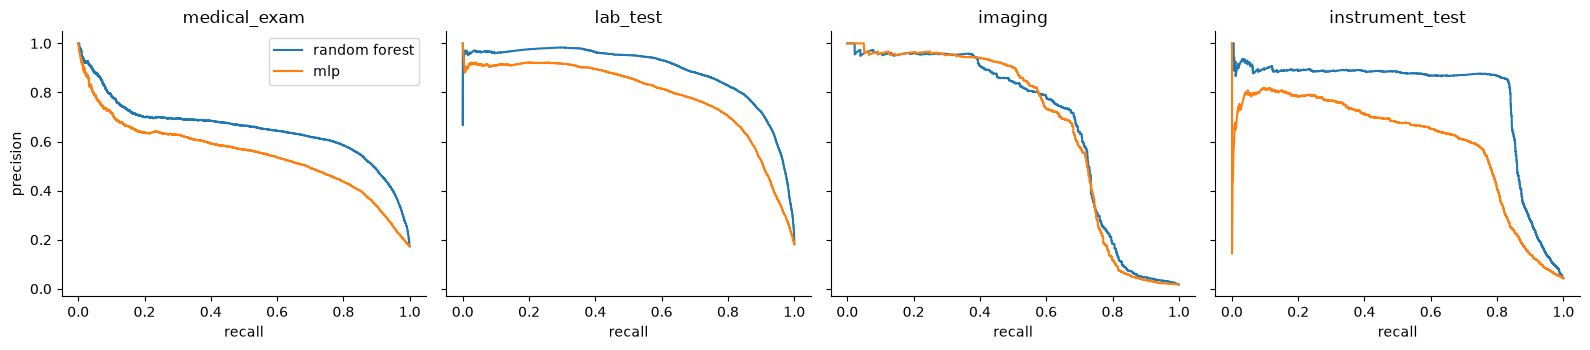

In [5]:
curves = {"random forest": forest_scores, "mlp": mlp_scores}

from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for column, (label, ax) in enumerate(zip(LABELS, axes)):
    for name, scores in curves.items():
        precision, recall, _ = precision_recall_curve(y_true[:, column], scores[:, column])
        ax.plot(recall, precision, label=name)
    ax.set(title=label, xlabel="recall")
axes[0].set_ylabel("precision")
axes[0].legend()
plt.tight_layout()

## Which features matter?
One forest fitted on the first training fold; importance = average impurity decrease.

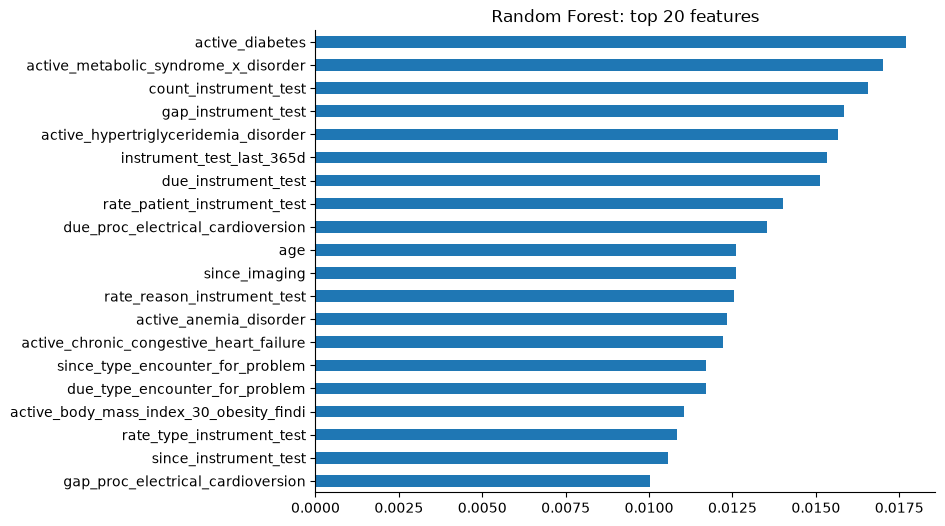

In [6]:
from workflow_ml.models.forest import ForestModel

forest = ForestModel().fit(table, folds[0][0])
importance = pd.Series(forest.forest.feature_importances_, index=forest.columns)
importance.nlargest(20).iloc[::-1].plot.barh(figsize=(8, 6), title="Random Forest: top 20 features");